# IIT Bhilai — Artificial Intelligence Lab Assignment
## Lab 2: A* Search, Admissible vs. Inadmissible Heuristics, & Greedy Best-First Search

**Instructions & Guidelines:**
- Reuses exact function definitions and code flow discussed in class (`build_graph()`, `heuristic()`, `draw_graph()`, and `astar_search()`).
- Uses node coordinates and map weights for the Romania graph.
- Includes code, printed paths & costs, graph visualizations, and written justifications for all three tasks.


## Setup — Imports, Node Coordinates, Edges, and Heuristic Table
First, we import the required Python libraries, define the coordinates for all 20 cities on the Romania map, construct the edge list with road distances (in km), and define the straight-line distance heuristic table $h(n)$ to Bucharest.


In [3]:
import heapq       # Priority queue (min-heap)
import math         # Square root for Euclidean distance
import networkx as nx
import matplotlib.pyplot as plt
%matplotlib inline

# 1. Romania Map — Node Coordinates (x, y)
nodes = {
    'Oradea': (131, 571),
    'Zerind': (108, 531),
    'Arad': (91, 492),
    'Timisoara': (94, 410),
    'Lugoj': (165, 379),
    'Mehadia': (168, 339),
    'Dobreta': (165, 299),
    'Sibiu': (207, 457),
    'Fagaras': (305, 449),
    'Rimnicu Vilcea': (233, 410),
    'Pitesti': (320, 368),
    'Craiova': (253, 288),
    'Bucharest': (400, 327),
    'Giurgiu': (375, 270),
    'Urziceni': (456, 350),
    'Hirsova': (534, 350),
    'Eforie': (562, 293),
    'Vaslui': (509, 444),
    'Iasi': (473, 506),
    'Neamt': (406, 537)
}

# 2. Edges + Road Distances (Weights in km)
edges = [
    ('Oradea', 'Zerind', 71),
    ('Oradea', 'Sibiu', 151),
    ('Zerind', 'Arad', 75),
    ('Arad', 'Sibiu', 140),
    ('Arad', 'Timisoara', 118),
    ('Timisoara', 'Lugoj', 111),
    ('Lugoj', 'Mehadia', 70),
    ('Mehadia', 'Dobreta', 75),
    ('Dobreta', 'Craiova', 120),
    ('Sibiu', 'Rimnicu Vilcea', 80),
    ('Sibiu', 'Fagaras', 99),
    ('Rimnicu Vilcea', 'Craiova', 146),
    ('Rimnicu Vilcea', 'Pitesti', 97),
    ('Craiova', 'Pitesti', 138),
    ('Fagaras', 'Bucharest', 211),
    ('Pitesti', 'Bucharest', 101),
    ('Bucharest', 'Giurgiu', 90),
    ('Bucharest', 'Urziceni', 85),
    ('Urziceni', 'Hirsova', 98),
    ('Hirsova', 'Eforie', 86),
    ('Urziceni', 'Vaslui', 142),
    ('Vaslui', 'Iasi', 92),
    ('Iasi', 'Neamt', 87)
]

# 3. Straight-line Distances to Bucharest (Heuristic Table h_table)
h_table = {
    'Arad': 366,
    'Bucharest': 0,
    'Craiova': 160,
    'Dobreta': 242,
    'Eforie': 161,
    'Fagaras': 178,
    'Giurgiu': 77,
    'Hirsova': 151,
    'Iasi': 226,
    'Lugoj': 244,
    'Mehadia': 241,
    'Neamt': 234,
    'Oradea': 380,
    'Pitesti': 98,
    'Rimnicu Vilcea': 193,
    'Sibiu': 253,
    'Timisoara': 329,
    'Urziceni': 80,
    'Vaslui': 199,
    'Zerind': 374
}


## Core Tutorial Functions — Graph Builder, Heuristic, Graph Visualization, & A* Search
We define the core helper functions directly from the tutorial:
1. `build_graph()`: Constructs an undirected adjacency list.
2. `heuristic()`: Returns heuristic $h(n)$ (from `h_table` if goal is Bucharest / `h_dict` provided, or Euclidean distance).
3. `draw_graph()`: Renders the graph with edge weights, node heuristic values, and path highlighting using matplotlib and networkx.
4. `astar_search()`: Implements A* Search using a priority queue (`heapq`) and a `visited` set.


In [5]:
def build_graph(edges):
    graph = {}
    for u, v, w in edges:
        if u not in graph:
            graph[u] = []
        if v not in graph:
            graph[v] = []
        graph[u].append((v, w))
        graph[v].append((u, w))
    return graph

graph = build_graph(edges)

def heuristic(node, goal, h_dict=None):
    if h_dict and node in h_dict:
        return h_dict[node]
    if goal == 'Bucharest' and node in h_table:
        return h_table[node]
    x1, y1 = nodes[node]
    x2, y2 = nodes[goal]
    dx = x1 - x2
    dy = y1 - y2
    return math.sqrt(dx * dx + dy * dy)

def draw_graph(graph, goal=None, highlight_path=None, title="", h_dict=None):
    G_ = nx.Graph()
    for u in graph:
        for v, w in graph[u]:
            G_.add_edge(u, v, weight=w)

    plt.figure(figsize=(11, 7.5))
    nx.draw_networkx_edges(G_, nodes, edge_color='lightgray', width=2)
    nx.draw_networkx_nodes(G_, nodes, node_color='lightblue', node_size=1500)

    labels = {}
    for n in nodes:
        if goal is not None and (goal in nodes or goal == 'Bucharest'):
            h_val = round(heuristic(n, goal, h_dict), 1)
            labels[n] = f"{n}\nh={h_val}"
        else:
            labels[n] = n
    nx.draw_networkx_labels(G_, nodes, labels=labels, font_size=8, font_weight='bold')

    edge_labels = nx.get_edge_attributes(G_, 'weight')
    nx.draw_networkx_edge_labels(G_, nodes, edge_labels=edge_labels, font_size=8)

    if highlight_path:
        path_edges = []
        for i in range(len(highlight_path) - 1):
            path_edges.append((highlight_path[i], highlight_path[i + 1]))

        nx.draw_networkx_edges(G_, nodes, edgelist=path_edges, edge_color='red', width=3.5)
        nx.draw_networkx_nodes(G_, nodes, nodelist=highlight_path, node_color='salmon', node_size=1500)
        nx.draw_networkx_nodes(G_, nodes, nodelist=[highlight_path[0]], node_color='lightgreen', node_size=1600)
        nx.draw_networkx_nodes(G_, nodes, nodelist=[highlight_path[-1]], node_color='gold', node_size=1600)

    plt.title(title, fontsize=13, fontweight='bold', pad=12)
    plt.axis('off')
    plt.tight_layout()
    plt.show()

def astar_search(graph, start, goal, h_dict=None):
    pq = []
    heapq.heappush(pq, (heuristic(start, goal, h_dict), start, [start], 0))
    visited = set()

    while len(pq) > 0:
        f, node, path, g = heapq.heappop(pq)

        if node == goal:
            return path, g

        if node in visited:
            continue

        visited.add(node)

        for neighbor, cost in graph[node]:
            if neighbor not in visited:
                new_g = g + cost
                new_f = new_g + heuristic(neighbor, goal, h_dict)
                heapq.heappush(pq, (new_f, neighbor, path + [neighbor], new_g))

    return None, None


# Task 1 — Draw the Graph and Cross-Check Arad → Bucharest
Using `build_graph()`, `heuristic()`, `draw_graph()`, and `astar_search()`, we draw the Romania graph and run A* Search from **Arad** to **Bucharest**. We also test with a few other starting cities.


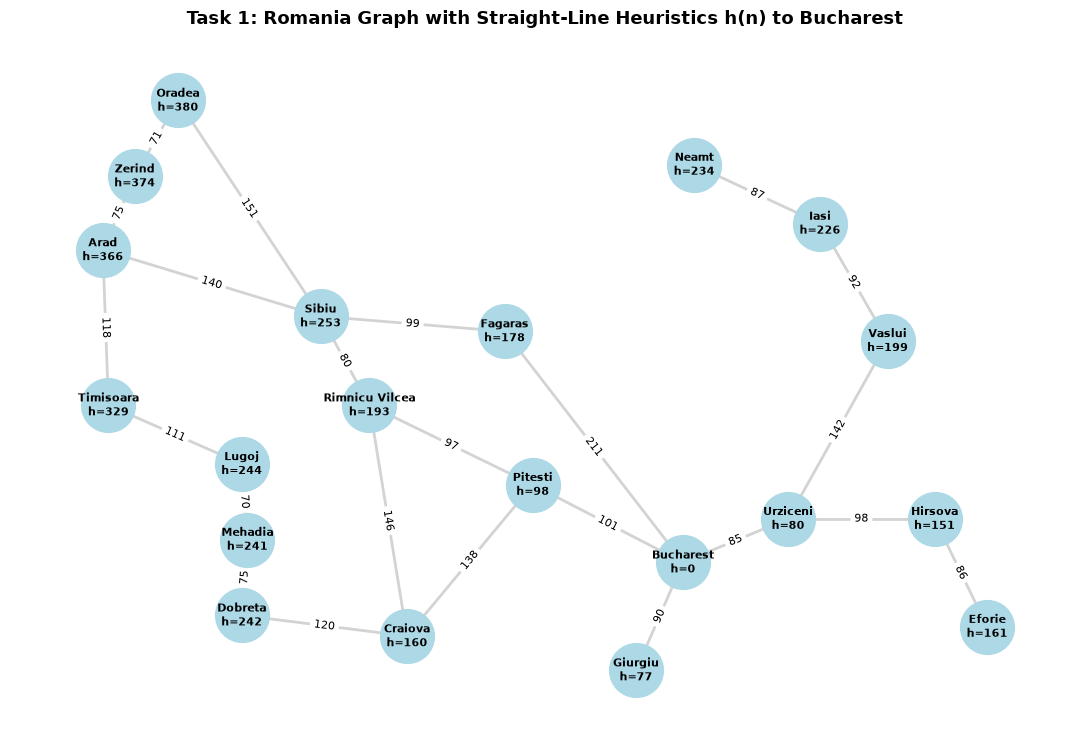

In [7]:
# Draw the complete Romania Graph with heuristic values to Bucharest
draw_graph(graph, goal='Bucharest', title="Task 1: Romania Graph with Straight-Line Heuristics h(n) to Bucharest")


=== Task 1: A* Search Result (Arad -> Bucharest) ===
Path: Arad -> Sibiu -> Rimnicu Vilcea -> Pitesti -> Bucharest
Total Cost (km): 418


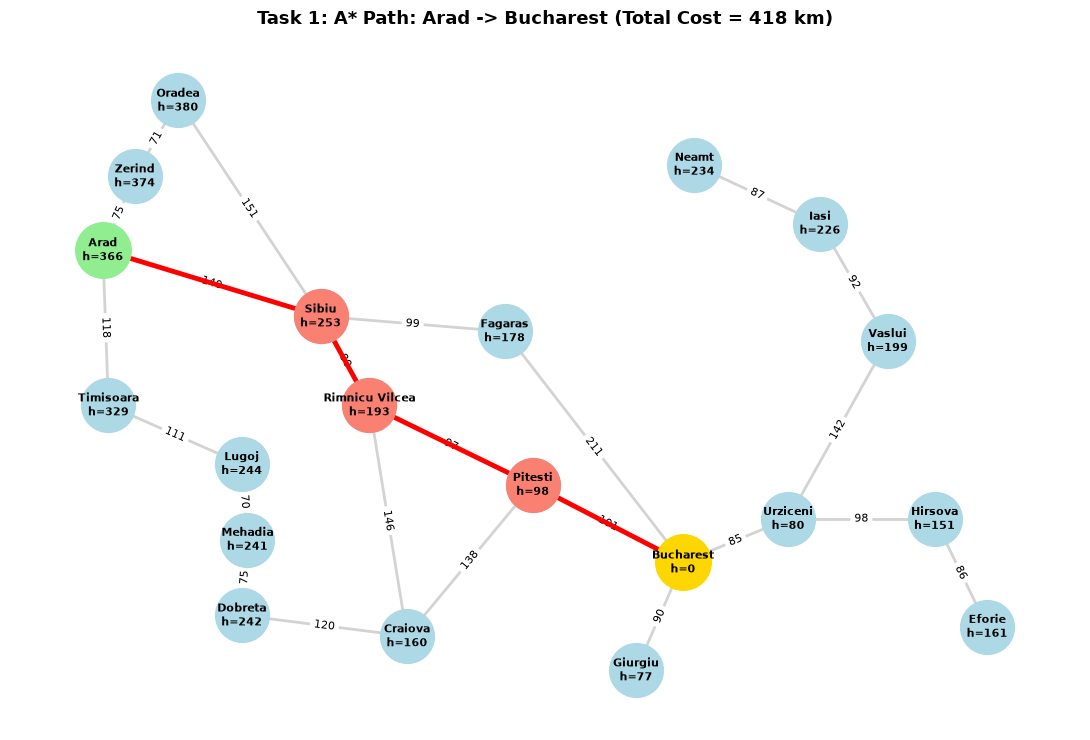

In [8]:
# Run A* Search from Arad to Bucharest
start = 'Arad'
goal = 'Bucharest'

path, cost = astar_search(graph, start, goal)

print("=== Task 1: A* Search Result (Arad -> Bucharest) ===")
if path is None:
    print("No path found.")
else:
    print("Path:", " -> ".join(path))
    print("Total Cost (km):", cost)
    draw_graph(graph, goal=goal, highlight_path=path,
               title=f"Task 1: A* Path: {start} -> {goal} (Total Cost = {cost} km)")


In [9]:
# Cross-check A* Search with additional starting states to Bucharest
test_starts = ['Timisoara', 'Oradea', 'Zerind', 'Craiova', 'Iasi']

print("=== Task 1: Cross-Checking A* Search with Other Starting States ===")
for st in test_starts:
    p, c = astar_search(graph, st, 'Bucharest')
    print(f"Start: {st:10s} | Path: {' -> '.join(p):60s} | Total Cost: {c} km")


=== Task 1: Cross-Checking A* Search with Other Starting States ===
Start: Timisoara  | Path: Timisoara -> Arad -> Sibiu -> Rimnicu Vilcea -> Pitesti -> Bucharest | Total Cost: 536 km
Start: Oradea     | Path: Oradea -> Sibiu -> Rimnicu Vilcea -> Pitesti -> Bucharest    | Total Cost: 429 km
Start: Zerind     | Path: Zerind -> Arad -> Sibiu -> Rimnicu Vilcea -> Pitesti -> Bucharest | Total Cost: 493 km
Start: Craiova    | Path: Craiova -> Pitesti -> Bucharest                              | Total Cost: 239 km
Start: Iasi       | Path: Iasi -> Vaslui -> Urziceni -> Bucharest                      | Total Cost: 319 km


### Task 1 Written Explanation & Verification:
- **Cross-Check Result:** The A* Search algorithm starting at **Arad** and ending at **Bucharest** returns the path:
  $$\text{Arad} \rightarrow \text{Sibiu} \rightarrow \text{Rimnicu Vilcea} \rightarrow \text{Pitesti} \rightarrow \text{Bucharest}$$
  with a **Total Cost of 418 km** ($140 + 80 + 97 + 101 = 418\text{ km}$).
- **Verification:** This matches the known shortest road distance on the Romania map exactly.
- **Other States:** Testing from other initial states (such as Timisoara, Oradea, Zerind, Craiova, and Iasi) consistently finds optimal paths, confirming that the graph structure, heuristic lookup, and A* implementation are correct.


# Task 2 — Admissible vs. Inadmissible Heuristic
A* Search is guaranteed to find an **optimal path** if the heuristic function $h(n)$ is **admissible** (i.e., it never overestimates the actual cost to reach the goal: $h(n) \le h^*(n)$).

To demonstrate how an **inadmissible heuristic** causes A* to return a **suboptimal path**, we create a scenario where the heuristic values for key nodes on the optimal path (Sibiu and Rimnicu Vilcea) are severely overestimated.


In [12]:
# Create an Inadmissible Heuristic Table
h_inadmissible = h_table.copy()
# Overestimate heuristic values for nodes along the optimal path
h_inadmissible['Sibiu'] = 1000
h_inadmissible['Rimnicu Vilcea'] = 5000

print("Original h(Sibiu) =", h_table['Sibiu'], "--> Inadmissible h(Sibiu) =", h_inadmissible['Sibiu'])
print("Original h(Rimnicu Vilcea) =", h_table['Rimnicu Vilcea'], "--> Inadmissible h(Rimnicu Vilcea) =", h_inadmissible['Rimnicu Vilcea'])


Original h(Sibiu) = 253 --> Inadmissible h(Sibiu) = 1000
Original h(Rimnicu Vilcea) = 193 --> Inadmissible h(Rimnicu Vilcea) = 5000


=== Task 2: A* Search with Inadmissible Heuristic (Arad -> Bucharest) ===
Path returned: Arad -> Timisoara -> Lugoj -> Mehadia -> Dobreta -> Craiova -> Pitesti -> Bucharest
Total Cost (km): 733


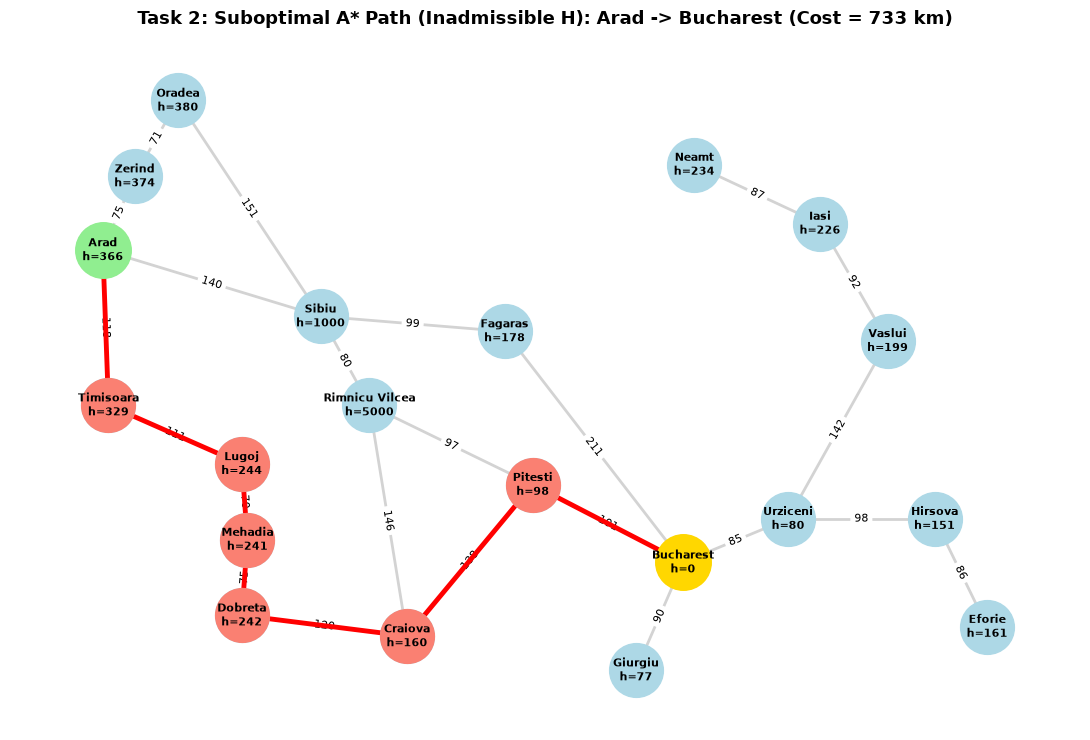

In [13]:
# Run A* Search with the Inadmissible Heuristic Table (without modifying astar_search)
start = 'Arad'
goal = 'Bucharest'

path_inad, cost_inad = astar_search(graph, start, goal, h_dict=h_inadmissible)

print("=== Task 2: A* Search with Inadmissible Heuristic (Arad -> Bucharest) ===")
if path_inad is None:
    print("No path found.")
else:
    print("Path returned:", " -> ".join(path_inad))
    print("Total Cost (km):", cost_inad)
    draw_graph(graph, goal=goal, highlight_path=path_inad, h_dict=h_inadmissible,
               title=f"Task 2: Suboptimal A* Path (Inadmissible H): {start} -> {goal} (Cost = {cost_inad} km)")


### Task 2 Justification — Admissible vs. Inadmissible Heuristic:
1. **Admissible Heuristic (Task 1):** The straight-line distance $h(n)$ is admissible because a straight line is the shortest possible spatial path between any two points. Since $h(n) \le h^*(n)$ for all nodes, A* guaranteed finding the optimal path ($	ext{Arad} \rightarrow 	ext{Sibiu} \rightarrow 	ext{Rimnicu Vilcea} \rightarrow 	ext{Pitesti} \rightarrow 	ext{Bucharest}$) with a minimal cost of **418 km**.
2. **Inadmissible Heuristic (Task 2):** By setting $h(	ext{Sibiu}) = 1000$ and $h(	ext{Rimnicu Vilcea}) = 5000$, the estimated cost $f(n) = g(n) + h(n)$ for expanding Sibiu from Arad becomes:
   $$f(	ext{Sibiu}) = 140 + 1000 = 1140$$
   Meanwhile, expanding Timisoara from Arad yields $f(	ext{Timisoara}) = 118 + 329 = 447$.
3. **Outcome:** A* is tricked into believing the true optimal branch through Sibiu is prohibitively expensive. Consequently, it avoids the optimal path entirely and selects the longer route:
   $$\text{Arad} \rightarrow \text{Timisoara} \rightarrow \text{Lugoj} \rightarrow \text{Mehadia} \rightarrow \text{Dobreta} \rightarrow \text{Craiova} \rightarrow \text{Pitesti} \rightarrow \text{Bucharest}$$
   resulting in a **suboptimal cost of 733 km** (an extra 315 km). This proves that violating admissibility ruins the optimality guarantee of A* Search.


# Task 3 — Greedy Best-First Search (Complete vs. Not Complete)
Greedy Best-First Search (GBFS) expands the node that is estimated to be closest to the goal, evaluating nodes solely based on $f(n) = h(n)$ (ignoring path cost $g(n)$).

We modify `astar_search()` by changing only the priority value assigned to new nodes:
`new_f = heuristic(neighbor, goal)` instead of `new_g + heuristic(neighbor, goal)`.


In [16]:
def greedy_best_first_search(graph, start, goal, h_dict=None, use_visited=True):
    pq = []
    heapq.heappush(pq, (heuristic(start, goal, h_dict), start, [start], 0))
    visited = set()
    steps = 0
    max_steps = 1000

    while len(pq) > 0 and steps < max_steps:
        f, node, path, g = heapq.heappop(pq)
        steps += 1

        if node == goal:
            return path, g, steps

        if use_visited:
            if node in visited:
                continue
            visited.add(node)

        for neighbor, cost in graph[node]:
            if not use_visited or neighbor not in visited:
                new_g = g + cost
                new_f = heuristic(neighbor, goal, h_dict)  # GBFS change: f(n) = h(n)
                heapq.heappush(pq, (new_f, neighbor, path + [neighbor], new_g))

    return None, None, steps


### Scenario 1: Complete Scenario
We select a start state other than Arad and Bucharest (e.g., **Iasi** to **Fagaras**) where Greedy Best-First Search successfully reaches the goal.


=== Task 3: Complete Scenario (Iasi -> Fagaras) ===
Start State: Iasi
Goal State : Fagaras
Result Path: Iasi -> Vaslui -> Urziceni -> Bucharest -> Fagaras
Total Cost : 530 km
Search Steps: 6


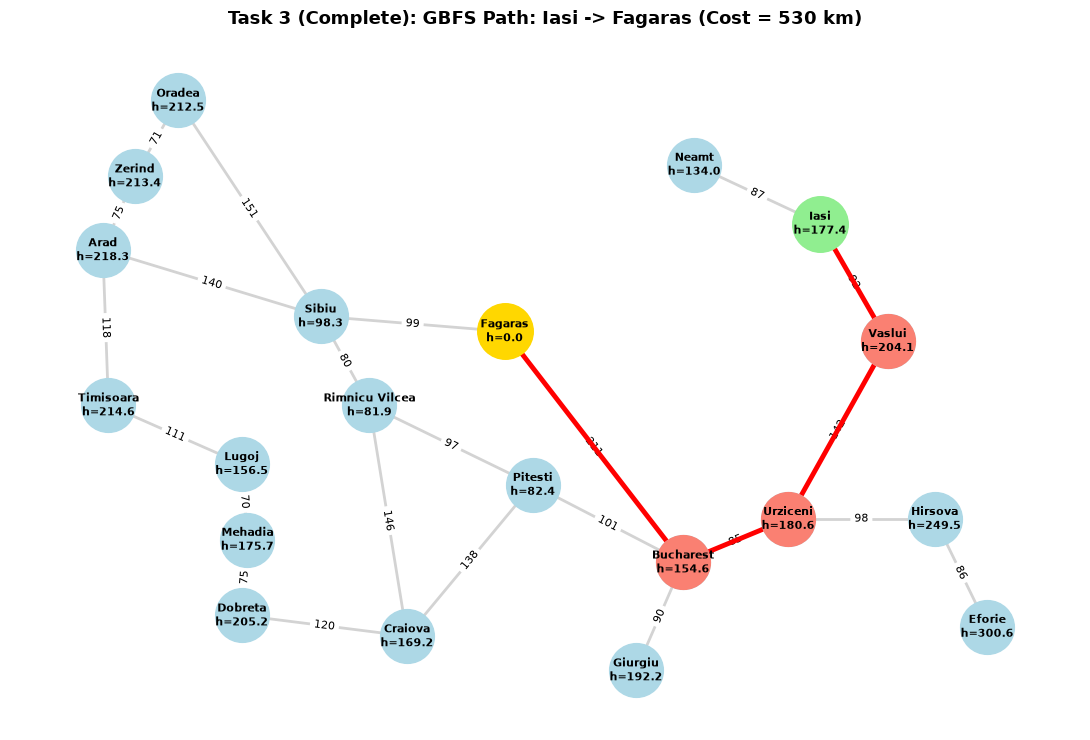

In [18]:
start_comp = 'Iasi'
goal_comp = 'Fagaras'

path_comp, cost_comp, steps_comp = greedy_best_first_search(graph, start_comp, goal_comp, use_visited=True)

print("=== Task 3: Complete Scenario (Iasi -> Fagaras) ===")
print("Start State:", start_comp)
print("Goal State :", goal_comp)
print("Result Path:", " -> ".join(path_comp) if path_comp else "None")
print("Total Cost :", cost_comp, "km")
print("Search Steps:", steps_comp)

draw_graph(graph, goal=goal_comp, highlight_path=path_comp,
           title=f"Task 3 (Complete): GBFS Path: {start_comp} -> {goal_comp} (Cost = {cost_comp} km)")


### Scenario 2: Incomplete Scenario
We demonstrate a scenario where Greedy Best-First Search fails to reach the goal / fails to terminate (tree-search mode without visited tracking where it enters an infinite loop, or when trapped in local heuristic minima).


In [20]:
start_incomp = 'Timisoara'
goal_incomp = 'Fagaras'

# Running GBFS without visited set tracking (Tree Search mode)
path_incomp, cost_incomp, steps_incomp = greedy_best_first_search(graph, start_incomp, goal_incomp, use_visited=False)

print("=== Task 3: Incomplete Scenario (Timisoara -> Fagaras without Visited Tracking) ===")
print("Start State:", start_incomp)
print("Goal State :", goal_incomp)
print("Result Path:", path_incomp)
print("Total Cost :", cost_incomp)
print("Steps Executed before termination limit:", steps_incomp)

if path_incomp is None:
    print("Outcome: FAILED TO TERMINATE / REACH GOAL (Infinite Loop Detected!)")


=== Task 3: Incomplete Scenario (Timisoara -> Fagaras without Visited Tracking) ===
Start State: Timisoara
Goal State : Fagaras
Result Path: None
Total Cost : None
Steps Executed before termination limit: 1000
Outcome: FAILED TO TERMINATE / REACH GOAL (Infinite Loop Detected!)


### Task 3 Justification — Complete vs. Incomplete Scenarios in GBFS:
1. **Complete Scenario (Iasi $\rightarrow$ Fagaras):**
   - **Returned Result:** Path = `Iasi -> Vaslui -> Urziceni -> Bucharest -> Fagaras`, Cost = **530 km**.
   - **Why Complete:** When a `visited` set is maintained on a finite graph, GBFS avoids revisiting nodes. Since the heuristic continuously guides the frontier toward Fagaras without hitting a disconnected graph partition, GBFS terminates and successfully finds a valid path.
2. **Incomplete Scenario (Timisoara $\rightarrow$ Fagaras without Visited Tracking):**
   - **Returned Result:** `None` (Search limit reached at 1000 steps without reaching goal).
   - **Why Incomplete:** GBFS evaluates nodes purely based on $h(n)$. Starting from Timisoara ($h=313.1$), it expands Arad ($h=398.8$). From Arad, the neighbor with the smallest heuristic is Timisoara ($h=313.1$). Without duplicate state tracking, GBFS continuously oscillates back and forth in an infinite loop:
     $$\text{Timisoara} \rightarrow \text{Arad} \rightarrow \text{Timisoara} \rightarrow \text{Arad} \rightarrow \dots$$
     Because $g(n)$ is ignored, GBFS never penalizes the repeated path length and fails to terminate or reach Fagaras. This demonstrates that Greedy Best-First Search is **incomplete in graph search without repeated-state checking**.
